# 언어모델 & 생성모델 요약본

## 1. NLP와 언어 모델

### 1-1. NLP (Natural Language Processing)

**1) 자연어 vs 프로그래밍 언어**
- 자연어: 인간이 의사소통을 위해 사용하는 언어, 일대다 대응 형식 → 유연하지만 모호성이 높음
- 프로그래밍 언어: 컴퓨터에 명령을 전달하기 위해 설계된 언어, 일대일 대응 형식 → 상대적으로 명확하고 엄격함

**2) 자연어의 특징**
| 특징 | 내용 | NLP에 필요한 것 |
|---|---|---|
| 이산적 데이터 (Discreteness) | 단어, 문자 등 구분된 기호로 구성 -> 수학적 처리가 어려움 | 단어와 문장을 숫자 또는 연속적인 벡터로 변환 (Embedding) |
| 순차적 데이터 (Sequentiality) | 단어의 등장 순서에 따라 문장의 의미가 달라짐 | 앞뒤 문맥을 함께 고려하는 모델 구조 (RNN, Transformer 등) |
| 중의성과 모호성 (Ambiguity) | 하나의 단어나 문장이 여러 의미로 해석될 수 있음 (예: 배 = 신체 부위, 과일, 선박) | 문맥 전체를 파악하여 적절한 의미 판단 |
| 희소성 (Sparsity) | 단어의 종류와 조합이 매우 다양하여 모든 표현을 학습하기 어려움 | 학습하지 않은 표현도 단어 간 유사도로 확률적으로 추론 |
| 가변성과 진화 (Variability & Evolution) | 신조어, 줄임말 등 언어가 시대와 환경에 따라 계속 변화 | 데이터로부터 유연하게 패턴을 학습하는 머신러닝 방식 |

**3) NLP의 개념**
- 인간이 일상생활에서 사용하는 자연어를 컴퓨터가 분석하고 이해하며 생성할 수 있도록 하는 인공지능 기술
- 자연어를 컴퓨터가 처리할 수 있는 숫자(벡터) 형태로 변환하고 단어 간 관계와 문맥을 분석
- 활용 분야: 기계 번역, 감성 분석, 텍스트 분류, 문서 요약, 질의응답 및 챗봇

**4) NLP의 분석 단계**

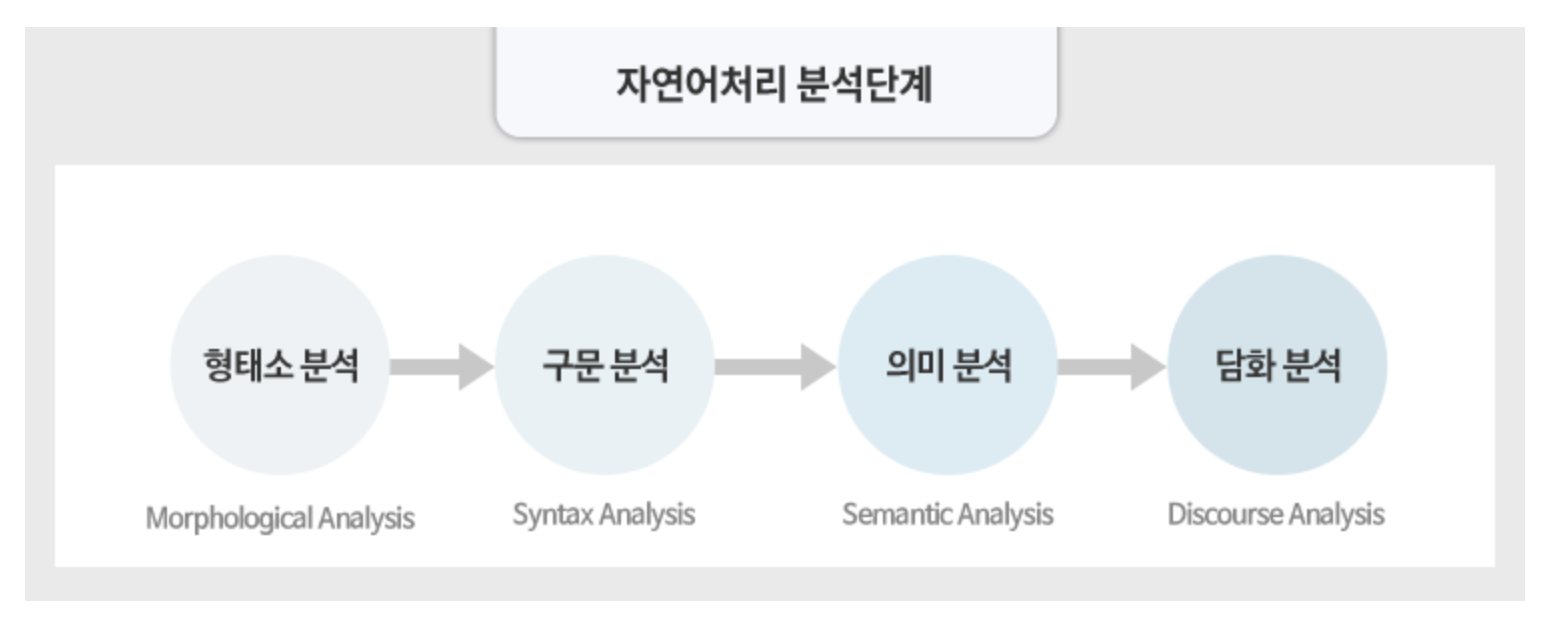

| 단계 | 내용 | 예시 |
|---|---|---|
| 형태소 분석 | 문장을 의미를 가진 가장 작은 단위인 형태소로 나누고 품사 분석 | "나는 학교에 간다" → 나/대명사 + 는/조사 + … |
| 구문 분석 | 단어들이 어떤 문법적 관계로 연결되는지 파악 | 철수(주어), 사과(목적어), 먹었다(서술어) |
| 의미 분석 | 문맥에 맞는 단어와 문장의 의미 파악 | "은행에서 돈을 찾았다" → '은행' = 금융기관 |
| 담화 분석 | 여러 문장 사이의 연결 관계와 전체 대화의 맥락 파악 | "그는 매우 기뻐했다" → '그' = 철수 |


### 1-2. 언어 모델

**1) 정의**
- 대량의 텍스트 데이터를 학습하여 단어 또는 토큰의 등장 확률을 예측하고 문장의 자연스러움을 판단하는 모델
- 쉽게 말하면, 인간이 말하고 쓰는 방식을 모방하는 시스템
   - 앞에 등장한 단어와 문맥을 바탕으로 다음에 나올 가능성이 높은 단어 예측
   - 단어들의 등장 확률을 계산하여 문장 전체의 자연스러움 평가 (확률이 높은 문장 = 자연스러운 문장)

> 언어 모델은 학습 방식에 따라 통계적 언어 모델(SLM)과 신경망 언어 모델(NLM)로 구분

## 2. 통계적 언어 모델 (SLM)

### 2-1. SLM과 분포 가설

**1) 분포 가설 (Distributional Hypothesis)**
- 통계 기반 언어 모델(SLM)의 근거가 되는 아이디어
- 비슷한 문맥에서 등장하는 단어들은 서로 유사한 의미를 가질 가능성이 높다는 가설
   - 단어의 의미는 해당 단어가 어떤 단어들과 함께 등장하는지를 통해 파악할 수 있다는 관점
   - 이후 단어 간 의미적 유사성을 학습하는 임베딩 기술의 이론적 기반이 됨

**2) 분포 가설을 설명하는 확률**
| 구분 | 내용 |
|---|---|
| 조건부 확률 | 특정 사건이 발생했다는 조건 아래 다른 사건이 발생할 확률 → 앞에 등장한 단어들을 조건으로 다음 단어의 등장 확률 계산 |
| 카운트 기반 확률 | 특정 문맥 다음에 어떤 단어가 얼마나 자주 등장했는지 계산 → 등장 빈도가 높은 단어일수록 높은 확률 부여 |

**3) 카운트 기반 모델의 한계: 희소 문제 (Sparsity Problem)**
- 가능한 단어 조합이 매우 많아 특정 표현이 학습 데이터에 거의 등장하지 않거나 전혀 등장하지 않는 문제
   - 카운트 기반 모델은 학습 데이터에서 관측된 단어의 등장 빈도에 의존
   - 한 번도 등장하지 않은 단어 조합은 확률을 0으로 계산할 수 있음
   - 실제로 자연스러운 표현이더라도 학습 데이터에 없으면 적절한 확률을 부여하기 어려움

> 희소 문제를 완화하기 위한 확률 추정 기법과 새로운 언어 모델이 필요


### 2-2. N-gram

**1) N-gram이 나오게 된 배경**
- SLM은 이전에 등장한 단어들을 바탕으로 다음 단어의 등장 확률을 계산하지만, 문장이 길어질수록 한계 발생
   - 데이터 희소성: 고려해야 할 단어 조합이 증가하면서 학습 데이터에 등장하지 않은 조합이 많아짐
   - 계산의 복잡성: 이전의 모든 단어를 고려할 경우 확률을 계산하고 저장하는 데 많은 자원이 필요
- 이를 완화하기 위해 N-gram 모델 등장

**2) 정의**
- 연속된 N개의 단어로 구성된 묶음으로, 직전 N-1개의 단어를 바탕으로 다음 단어의 등장 확률을 예측하는 통계적 언어 모델
   - 이전의 모든 단어 대신 가장 최근 N-1개의 단어만 활용
   - N이 커질수록 더 긴 문맥을 반영할 수 있음

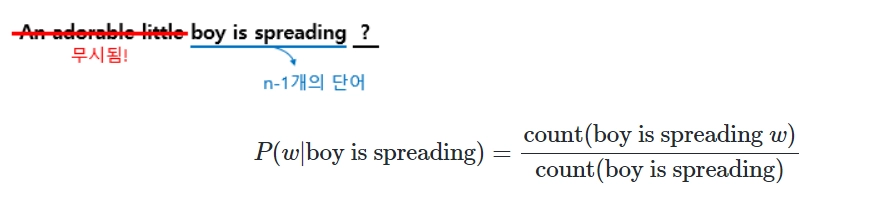

$$
P(w \mid \text{boy is spreading}) = \frac{\text{count}(\text{boy is spreading } w)}{\text{count}(\text{boy is spreading})}
$$

- 예 (N=4): P(insults | boy is spreading) = 0.500, P(smiles | boy is spreading) = 0.200 → 'insults'의 등장 확률이 더 높다고 예측

**3) SLM과 N-gram의 관계**
- 공통점: 단어의 등장 빈도와 조건부 확률로 다음 단어를 예측하는 통계적 언어 모델
- 차이점
   - SLM: 이전에 등장한 모든 단어를 조건으로 확률을 표현할 수 있지만 긴 문맥에 대한 추정이 어려움
   - N-gram: 직전 N-1개의 단어만 고려 → 계산과 확률 추정이 상대적으로 단순

> N-gram은 SLM과 별개의 개념이 아닌, SLM의 확률 계산을 단순화하기 위해 문맥의 범위를 N-1개 단어로 제한한 대표적인 통계적 언어 모델

**4) N-gram의 한계**
| 한계 | 내용 |
|---|---|
| 희소 문제 | N값이 커질수록 가능한 단어 조합의 수가 급격하게 증가하여 훈련 데이터에서 특정 조합을 찾기 어려워짐, 등장하지 않은 N-gram은 확률 0 → 긴 문맥을 반영하려고 N을 높일수록 충분한 학습 데이터가 필요 |
| 문맥 제한 | 직전 N-1개의 단어만 고려하므로 멀리 떨어진 단어 사이의 관계를 파악하기 어려움, 문장이 길어질수록 앞부분의 중요한 정보가 예측에서 제외될 수 있음 |


### 2-3. Perplexity (PPL)

**1) 정의**
- 언어 모델이 주어진 문장을 예측할 때 얼마나 "혼란스러워하는지(perplexed)"를 수치로 나타낸 지표
   - PPL이 낮을수록: 예측 불확실성이 낮아 실제 등장한 단어를 잘 예측
   - PPL이 높을수록: 예측 불확실성이 높아 실제 등장한 단어를 예측하기 어려움

$$
PPL(W) = P(w_1, w_2, \dots, w_N)^{-\frac{1}{N}}
$$

**2) 특징**
- 문장 W의 빈도수와 PPL의 관계: 훈련 데이터에 희소하게 등장하는 문장일수록 PPL이 높아지는 경향, 자주 등장하는 문장은 상대적으로 PPL이 낮을 가능성이 높음
- 단어 개수 N과 PPL의 관계: 예측하기 쉬운 단어가 추가되면 평균 예측 난이도가 낮아져 PPL이 감소할 수 있음, 단 N이 증가한다고 PPL이 반드시 낮아지는 것은 아니며 추가된 단어의 예측 난이도에 따라 달라짐

**3) PPL의 사용**
- SLM뿐 아니라 NLM의 예측 성능을 평가하는 데에도 활용
   - SLM: 등장 빈도에 의존하므로 훈련 데이터에서 보지 못한 표현에 낮은 확률을 부여하기 쉬움
   - NLM: 임베딩과 신경망으로 단어 간 의미 관계와 문맥을 학습하여 새로운 문장에도 유연하게 대처 가능
- 따라서 NLM은 카운트 기반 SLM보다 낮은 PPL을 달성할 수 있으며, 이를 통해 예측 성능의 향상을 확인할 수 있음


## 3. 신경망 언어 모델 (NLM)

### 3-1. NLM의 등장과 임베딩

**1) NLM의 등장**
- 기존 SLM의 한계를 완화하기 위해 인공 신경망을 활용하여 단어의 의미와 문맥을 학습하는 신경망 언어 모델(NLM) 등장
   - 단어를 연속적인 숫자 벡터로 변환하여 단어 간 의미적 관계를 학습
   - 신경망을 통해 관측되지 않은 표현에도 일반화할 수 있도록 설계
   - 단순한 등장 빈도를 넘어 단어 간 관계와 문맥을 반영하여 다음 단어를 예측

**2) 키워드: 임베딩**
- 단어와 같은 이산적인 언어 데이터를 연속적인 숫자 벡터로 변환하여 단어 간 의미적 관계를 표현하는 기술

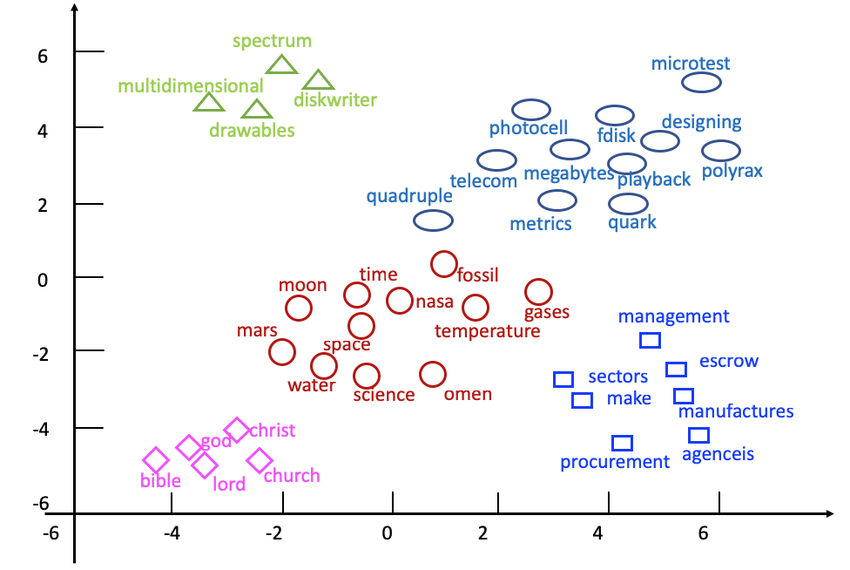

- SLM은 단어를 서로 다른 기호로 취급하지만, NLM은 단어를 고차원 벡터 공간의 한 점으로 표현
- 의미나 문맥이 유사한 단어들은 벡터 공간에서 서로 가까운 위치에 놓이도록 학습
- 이를 통해 단어 간 의미적 유사성을 파악하고 학습 데이터에 없는 표현에도 일반화 가능

### 3-2. SLM과 NLM의 차이

| 구분 | 통계적 언어 모델(SLM) | 신경망 언어 모델(NLM) |
|---|---|---|
| 학습 방식 | 단어 등장 빈도와 확률 계산 | 인공 신경망의 가중치 학습 |
| 단어 표현 | 단어를 개별 기호로 취급 | 단어를 연속적인 벡터로 표현 |
| 의미적 관계 | 유사 단어 간 관계 반영이 어려움 | 임베딩을 통해 의미적 유사성 학습 |
| 희소 문제 | 관측되지 않은 조합에 취약 | 학습된 표현을 통해 희소 문제 완화 |
| 문맥 처리 | N-gram은 직전 N-1개 단어만 고려 | 신경망 구조에 따라 다양한 범위의 문맥 학습 |
| 계산 비용 | 상대적으로 낮음 | 학습에 많은 연산 자원 필요 |

> NLM은 단어의 의미적 관계를 학습하고, 희소 문제를 완화해 일반화 능력을 높이며, RNN·LSTM·Transformer 등의 발전으로 긴 문맥도 효과적으로 처리할 수 있게 됨

## 4. 딥러닝 기반 언어 모델

### 4-1. Transformer의 등장
- RNN과 LSTM의 한계: 장기 의존성 문제, 기울기 소실 문제, 순차 처리의 비효율성
- 2017년 Google 연구진이 "Attention Is All You Need" 논문을 통해 Transformer 제안
   - Self-Attention을 통해 단어 간 관계와 장거리 문맥을 효과적으로 학습
   - 병렬 처리와 위치 인코딩으로 학습 효율을 높이고 단어의 순서 정보를 반영

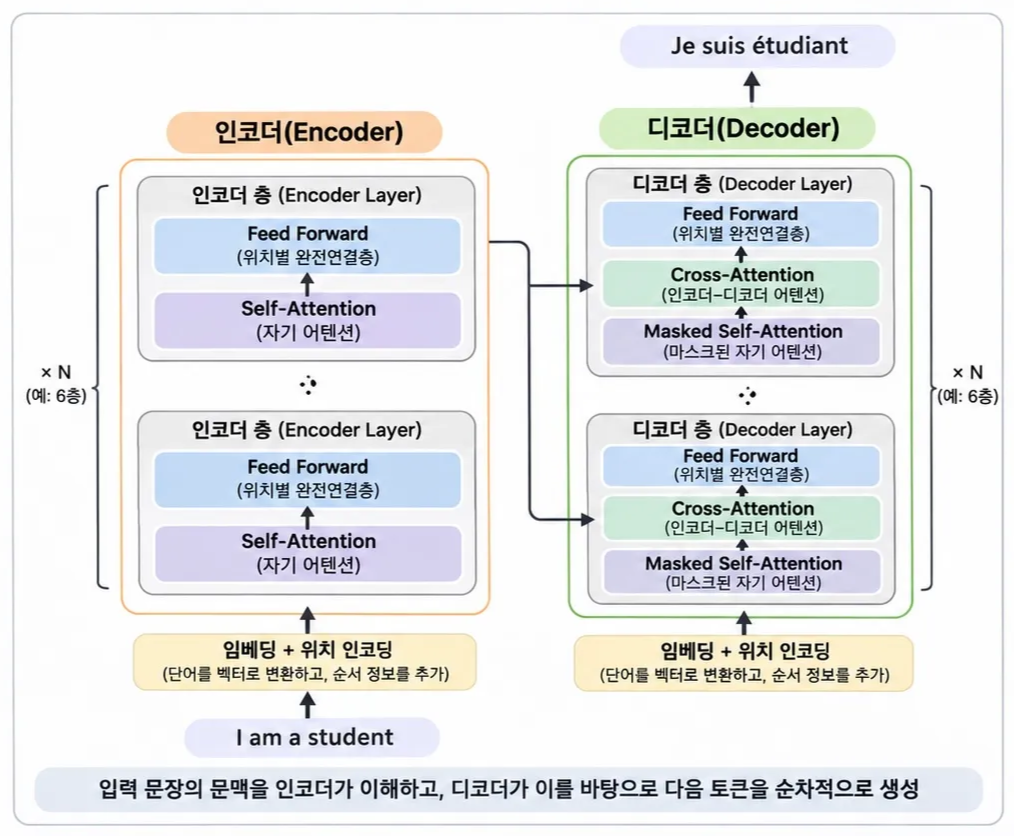

> Transformer는 RNN과 LSTM의 한계를 완화한 모델로, 이후 BERT와 GPT 등 현대 언어 모델의 기반이 됨

### 4-2. BERT

**1) 정의**
- Transformer의 인코더 구조를 기반으로 문장의 양방향 문맥을 학습하여 언어의 의미를 이해하는 신경망 언어 모델
   - B(Bidirectional): 단어의 앞뒤 문맥을 모두 고려하는 양방향 학습
   - ER(Encoder Representations): 인코더를 활용하여 문맥이 반영된 단어의 벡터 표현 생성
   - T(from Transformers): Transformer의 인코더 구조를 기반으로 설계된 모델

**2) 특징**
- 양방향: 특정 단어의 의미를 파악할 때 앞에 등장한 단어뿐 아니라 뒤에 등장한 단어까지 함께 고려
- Transformer 기반: 인코더 구조만 활용하여 Self-Attention으로 단어 간 관계 학습
- 사전학습(Pre-training) + 파인튜닝(Fine-tuning)
   - 사전학습: 대량의 텍스트 데이터로 언어의 일반적인 구조와 문맥 학습
   - 파인튜닝: 사전학습된 모델을 특정 작업의 데이터로 추가 학습하여 목적에 맞게 활용

**3) 학습 방법**

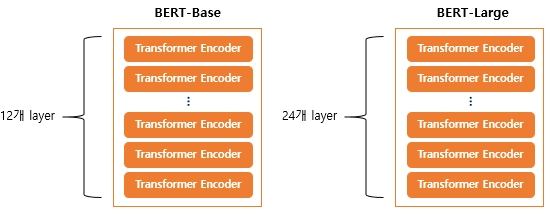

- 여러 개의 Transformer 인코더 층을 쌓은 구조
- 입력 문장 토큰화(문장 시작과 끝에 `[CLS]`, `[SEP]` 특수 토큰 추가) → 임베딩(토큰의 의미, 위치, 문장 구분 정보 반영) → Transformer Encoder를 통한 문맥 학습 → 문장 분류, 감성 분석, 질의응답 등 문장 이해 작업 수행

**4) 사전학습**
- 정답이 별도로 표시된 데이터 없이 텍스트 자체를 활용하여 학습하며, MLM과 NSP 두 가지 방법 사용

| 구분 | Masked Language Model (MLM) | Next Sentence Prediction (NSP) |
|---|---|---|
| 개념 | 입력 문장의 일부 토큰을 가린 뒤 주변 문맥으로 원래 토큰을 예측하는 빈칸 채우기 방식 | 두 번째 문장이 첫 번째 문장 바로 다음에 등장하는 문장인지 예측 |
| 학습 과정 | 일부 토큰을 무작위 선택 → 대부분을 `[MASK]`로 대체 → 앞뒤 문맥 분석 → 원래 토큰 예측 | 문장 A, B 입력 → 실제 다음 문장이면 `IsNext`, 무작위 문장이면 `NotNext`로 분류 |
| 학습 효과 | 양방향 문맥 이해 능력 향상, 문맥에 따라 달라지는 의미 학습 | 두 문장 사이의 연결 관계와 문맥적 연관성 학습 |

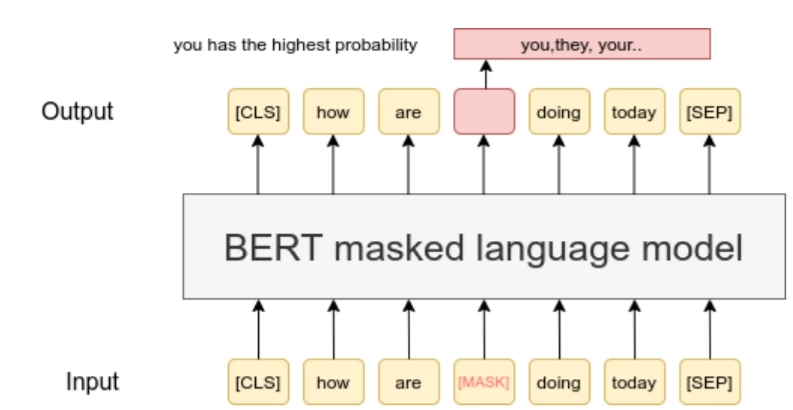

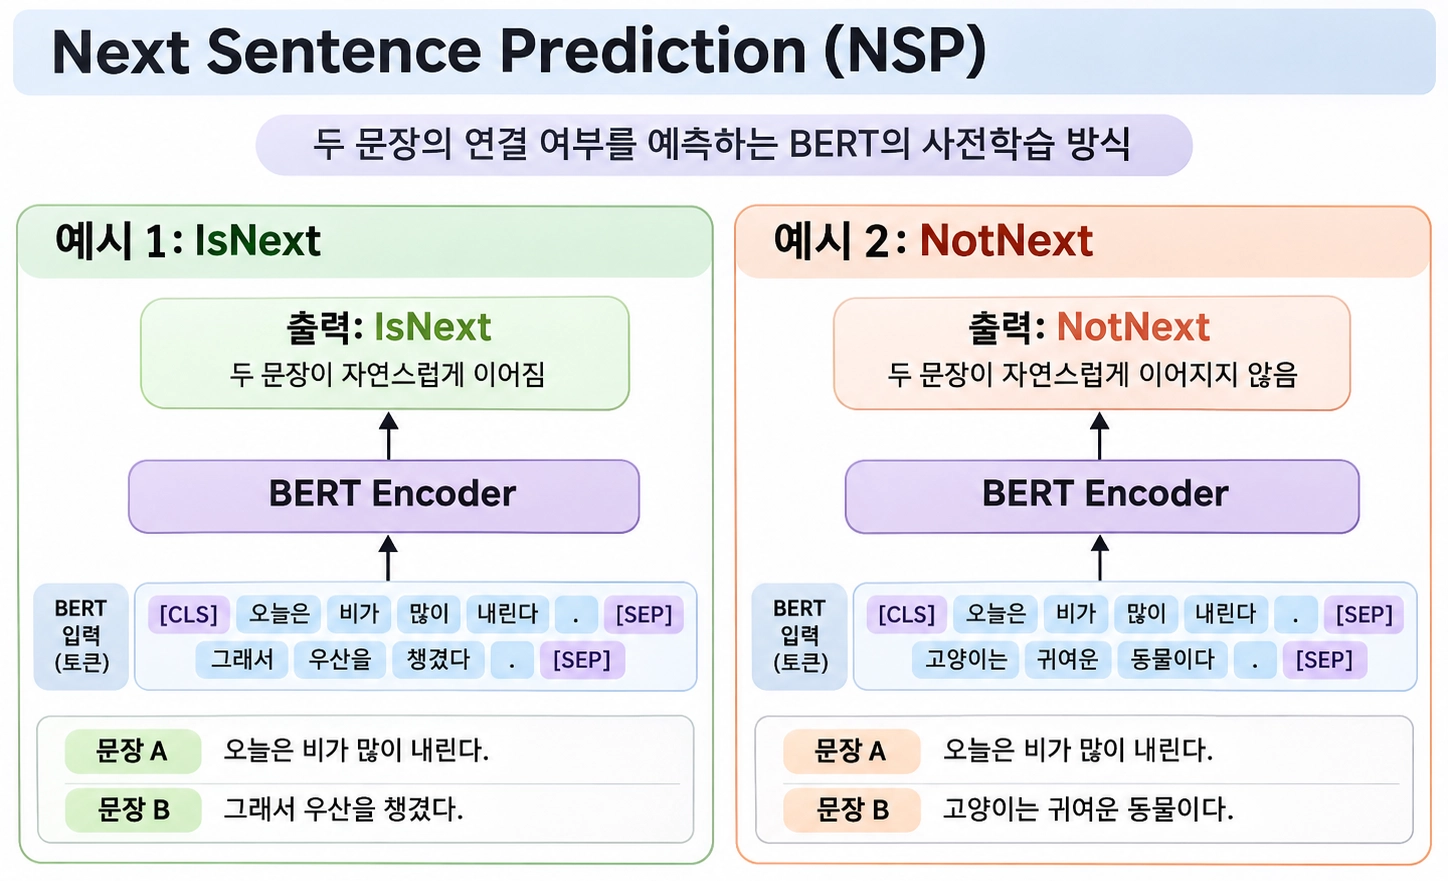

- BERT 이후 모델
   - RoBERTa: NSP를 제거하고 Dynamic Masking 적용, 더 많은 데이터와 큰 배치로 성능 향상
   - ALBERT: 임베딩 차원 축소와 계층 간 파라미터 공유로 파라미터 수 감소, NSP 대신 문장 순서 예측(SOP) 도입

### 4-3. GPT

**1) 정의**
- Transformer의 디코더 기반 구조를 활용하여 이전 단어들을 바탕으로 다음 단어를 예측하고 텍스트를 생성하는 언어 모델

**2) 초기 GPT의 구조**
- Decoder 기반: 인코더 없이 디코더 구조만 활용하며, 인코더와 연결되는 Cross-Attention은 사용하지 않음
- Masked Self-Attention: 미래 토큰을 참고하지 않고 이전 토큰들만 활용하여 다음 토큰 예측 (디코더의 핵심)
- Feed Forward Network: Attention 결과를 추가로 변환하여 언어적 특징 학습

> GPT는 이전 토큰을 바탕으로 다음 토큰을 순차적으로 예측하는 자기회귀 방식으로 텍스트를 생성

- GPT-3는 별도의 파인튜닝 없이 프롬프트의 지시와 예시만으로 다양한 작업을 수행하는 In-Context Learning 능력을 보여줌 (Zero-shot / One-shot / Few-shot)

**3) BERT vs GPT**
| 구분 | BERT | GPT |
|---|---|---|
| 기반 구조 | Transformer Encoder | Transformer Decoder 기반 |
| 방향성 | 양방향 | 단방향(자기회귀) |
| 학습 방법 | MLM, NSP(초기 BERT) | 다음 토큰 예측 |
| 주요 목적 | 언어 이해 및 문맥 분석 | 텍스트 생성 |
| 대표 Task | 감성 분석, 텍스트 분류, 개체명 인식 | 챗봇, 텍스트 생성, 번역, 요약 |

### 4-4. LLM (Large Language Model)

**1) 정의**
- 방대한 텍스트 데이터와 대규모 신경망을 활용하여 인간의 언어를 이해하고 생성하도록 학습된 인공지능 모델
   - 대량의 데이터에서 언어의 패턴과 문맥적 관계를 학습하여 다양한 자연어 처리 작업 수행
   - 대부분 Transformer 구조를 기반으로 하며, 텍스트 생성뿐 아니라 번역, 요약, 질의응답 등에도 활용
   - 예: GPT 계열(ChatGPT), LLaMA, Claude, Gemini 등

**2) 작동 방식**

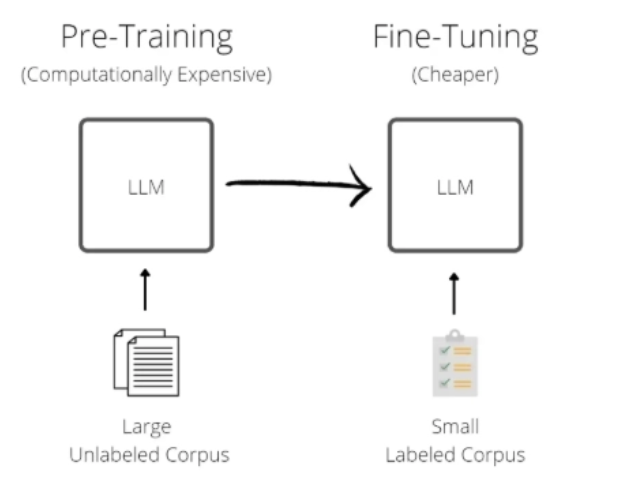

- 학습: 단순 암기를 넘어 단어 사이의 관계, 문맥적 의미, 문법 구조, 세상의 지식까지 언어의 패턴을 스스로 터득
   - 사전학습: 대량의 텍스트로 다음 토큰을 예측하는 작업을 반복하며 언어의 구조와 문맥 학습
   - 파인튜닝: 특정 작업이나 목적에 맞는 데이터로 추가 학습하여 성능 개선
- 예측: 입력 처리(토큰 분리, 벡터 변환) → 문맥 분석(Attention) → 다음 토큰 예측(확률 계산) → 결과 생성(확률이 가장 높은 단어를 순서대로 예측)

> LLM이 GPT 방식을 사용하게 된 이유: BERT는 입력 문장의 의미 이해에 중점을 두는 반면, GPT는 다음 토큰을 순차적으로 예측하여 텍스트 생성에 특화 → 새로운 문장을 생성해야 하는 대화형 LLM에서는 자기회귀 방식의 GPT 계열 구조가 널리 활용됨

**3) 한계**
- 환각 현상(Hallucination): 사실과 다르거나 존재하지 않는 정보를 그럴듯하게 생성하는 현상, 다음 토큰의 확률로 답변을 생성하므로 사실 여부가 항상 보장되지 않음
- 높은 학습 및 업데이트 비용: 사전학습에 막대한 연산 자원과 비용이 필요하고, 학습 이후 변경된 최신 정보가 자동으로 반영되지 않음

### 4-5. RAG의 구조

**1) 정의**
- 외부 지식 검색과 LLM의 텍스트 생성 능력을 결합하여 답변의 정확성과 최신성을 높이는 기술
- 기존 LLM은 학습 당시의 지식만 갖고 있어 이후 새롭게 나타난 지식에 대해서는 답변 불가 → 외부 정보를 검색하여 답변 생성에 활용

**2) 구조**

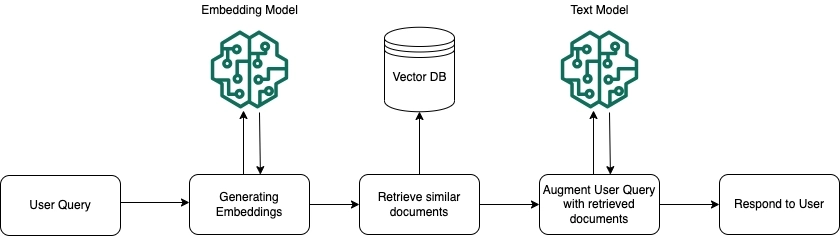

| 구성 요소 | 역할 |
|---|---|
| 질의 인코더 (Query Encoder) | 사용자의 질문을 임베딩 모델을 통해 숫자 벡터로 변환 → 관련성이 높은 문서를 검색할 수 있도록 함 |
| 지식 검색기 (Knowledge Retriever) | 벡터 데이터베이스(Vector DB)에서 질문 벡터와 유사도가 높은 문서를 검색하여 LLM에 전달 |
| 지식 증강 생성기 (Knowledge-Augmented Generator) | 사용자의 질문과 검색된 외부 문서를 결합하여 LLM에 입력 → 문서 내용을 참고하여 최종 답변 생성 |

**3) 장점**
- 최신 정보 반영: 모델을 재학습하지 않고도 외부 데이터베이스나 최신 문서를 검색하여 활용 가능
- 정보 정확성 향상: 검색된 외부 자료를 근거로 답변을 생성하여 환각 현상을 완화하고 신뢰성을 높임

- 참고: CAG (Credibility-aware Generation)
   - 기존 RAG는 검색된 문서가 오래되었거나 부정확할 수 있다는 한계
   - 검색된 정보의 관련성뿐 아니라 출처의 신뢰성, 최신성 등을 함께 평가하여 신뢰도가 높은 정보를 우선 활용


### 4-6. LangChain

**1) 정의**
- LLM을 외부 데이터, API, 다양한 도구와 연결하여 복잡한 AI 애플리케이션을 쉽게 개발할 수 있도록 지원하는 오픈소스 프레임워크

**2) 아이디어**
- 기존 LLM과 RAG를 구현할 때의 어려움: 구현의 복잡성, 외부 시스템 연동, 유지보수의 어려움
- 이를 해결하기 위해 LLM과 다양한 기능을 모듈화하고 연결하여 개발 효율성을 높이는 LangChain 등장

**3) 특징**
| 특징 | 내용 | 예시 |
|---|---|---|
| 추상화 | LLM 호출, 프롬프트 관리, 문서 검색 등 복잡한 기능을 간단한 인터페이스로 제공 | 복잡한 API 호출 코드 없이 간단한 명령으로 질문하고 답변 받기 |
| 표준화 | 서로 다른 LLM, 데이터베이스, 외부 도구를 일관된 방식으로 사용하도록 지원 | ChatGPT 대신 Claude를 쓸 때 모델 연결 부분만 변경 |
| 체이닝 | 여러 작업을 순서대로 연결하여 하나의 작업 흐름으로 구성 | 영어 문장 입력 → 번역 → 요약 → 결과 출력 |

**4) 관련 도구**
- LangGraph: LangChain은 선형적인 체인 구조에 적합 → 노드(Node)와 엣지(Edge)를 연결하여 조건부 분기, 반복 실행, 상태 관리가 가능한 비선형적 워크플로우 구현
- LangSmith: LLM 애플리케이션의 실행 과정 추적, 성능 평가, 운영 모니터링을 지원하는 개발 및 관리 플랫폼

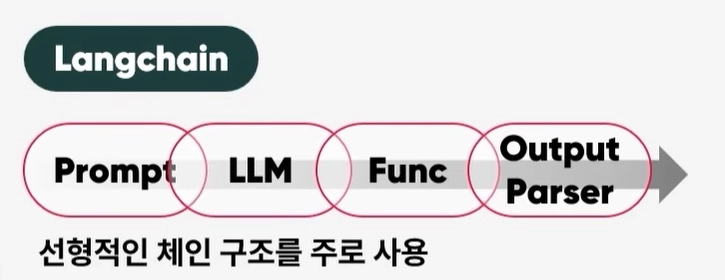
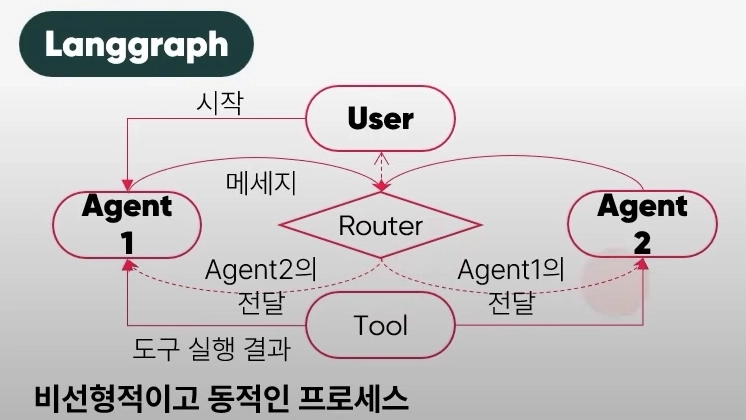

## 5. sLM (small Language Model)

### 5-1. sLM의 개념
- 자연어를 처리하고 이해하며 생성할 수 있는 AI 모델 중, LLM보다 규모와 범위가 작은 모델
- 일반적으로 수백만~수십억 개 수준의 매개변수를 가지며, LLM은 수십억~수천억 개 이상의 매개변수 사용
- 작고 효율적이어서 메모리와 연산 자원을 적게 사용 → 모바일 앱처럼 자원이 제한된 환경이나, 인터넷 연결 없이 기기 내부에서 응답하는 오프라인 추론에도 활용 가능

| 구분 | LLM | sLM |
|---|---|---|
| 모델 크기 | 상대적으로 큼 | 상대적으로 작음 |
| 성능 | 복잡한 추론과 다양한 작업에 강점 | 특정 분야나 비교적 단순한 작업에 효율적 |
| 연산 비용 | 상대적으로 높음 | 상대적으로 낮음 |
| 응답 속도 | 많은 연산이 필요할 수 있음 | 같은 환경에서 빠른 처리에 유리 |
| 활용 환경 | 주로 고성능 서버 | 서버, 스마트폰, 노트북 등 |

### 5-2. 모델 압축
- 모델의 중요한 성능은 최대한 유지하면서 크기와 연산량을 줄이는 기술 → 메모리 사용량과 계산 비용을 줄여 제한된 환경에서도 효율적으로 사용

| 기법 | 개념 | 작동 원리 | 효과 / 한계 |
|---|---|---|---|
| ① 가지치기 (Pruning) | 중요도가 낮은 연결이나 뉴런을 제거하여 크기와 연산량을 줄이는 방법 | 결과에 미치는 영향이 작은 부분을 찾아 제거하고 핵심 연결만 남김, 필요시 추가 학습으로 성능 보완 (비구조적 / 구조적 가지치기) | 크기·연산량 감소 / 중요한 부분까지 제거하면 성능 저하 |
| ② 양자화 (Quantization) | 숫자의 표현 정밀도를 낮춰 메모리 사용량과 연산 비용을 줄이는 방법 | FP32(32비트) 가중치를 FP16(16비트)이나 INT8(8비트) 등 낮은 정밀도로 변환 | 크기·메모리 감소, 속도 개선 / 정밀도가 낮아지며 일부 성능 저하 |
| ③ 저차원 분해 (Low-Rank Factorization) | 크고 복잡한 가중치 행렬을 더 작은 행렬들의 곱으로 근사하는 방법 | 큰 행렬을 작은 두 행렬로 나누어 중요한 특징을 적은 수의 파라미터로 표현 | 저장 공간과 연산량 감소 |
| ④ 지식 증류 (Knowledge Distillation) | 큰 모델(Teacher)의 지식을 작은 모델(Student)에 전달하는 방법 | 교사 모델의 예측 결과나 학습된 지식을 학생 모델이 따라 하도록 학습 | 적은 자원으로 효율적인 추론 가능 |

### 5-3. sLM의 장단점

| 구분 | 내용 |
|---|---|
| 장점: 성능적 측면 | 빠른 응답 속도 / 스마트폰, 노트북 등 제한된 환경에서도 실행 가능 / 기업 내부 서버나 개인 기기에서 직접 실행하여 외부로 데이터를 전송하지 않아도 되는 보안 및 데이터 보호 |
| 장점: 비용적 측면 | 낮은 운영 비용 / 적은 전력 소비 / 고성능 GPU 의존도를 낮춰 하드웨어 비용 절감 |
| 단점: 편향 (Bias) | 학습 데이터의 사회적 편견이나 잘못된 정보가 반영될 수 있으며, 데이터 다양성이 부족하면 특정 집단이나 관점에 치우친 결과 생성 |
| 단점: 제한된 일반화 및 성능 저하 | 학습하지 않은 새로운 상황이나 복잡한 추론, 전문 지식이 필요한 작업에서 LLM에 비해 정확도가 떨어질 수 있음 |
| 단점: 환각 현상 | LLM과 마찬가지로 근거가 없는 질문에 대해 사실과 다른 정보를 생성할 수 있음 |

### 5-4. sLM과 LLM의 결합: 결합 추론 (Hybrid Inference)
- sLM과 LLM을 함께 활용하여 각 모델의 장점을 살리는 방식
- sLM은 빠르고 비용이 적게 들지만 복잡한 작업에서 성능이 떨어질 수 있고, LLM은 복잡한 문제 해결에 유리하지만 많은 자원과 비용이 필요 → 작업의 난이도에 따라 적절한 모델 활용

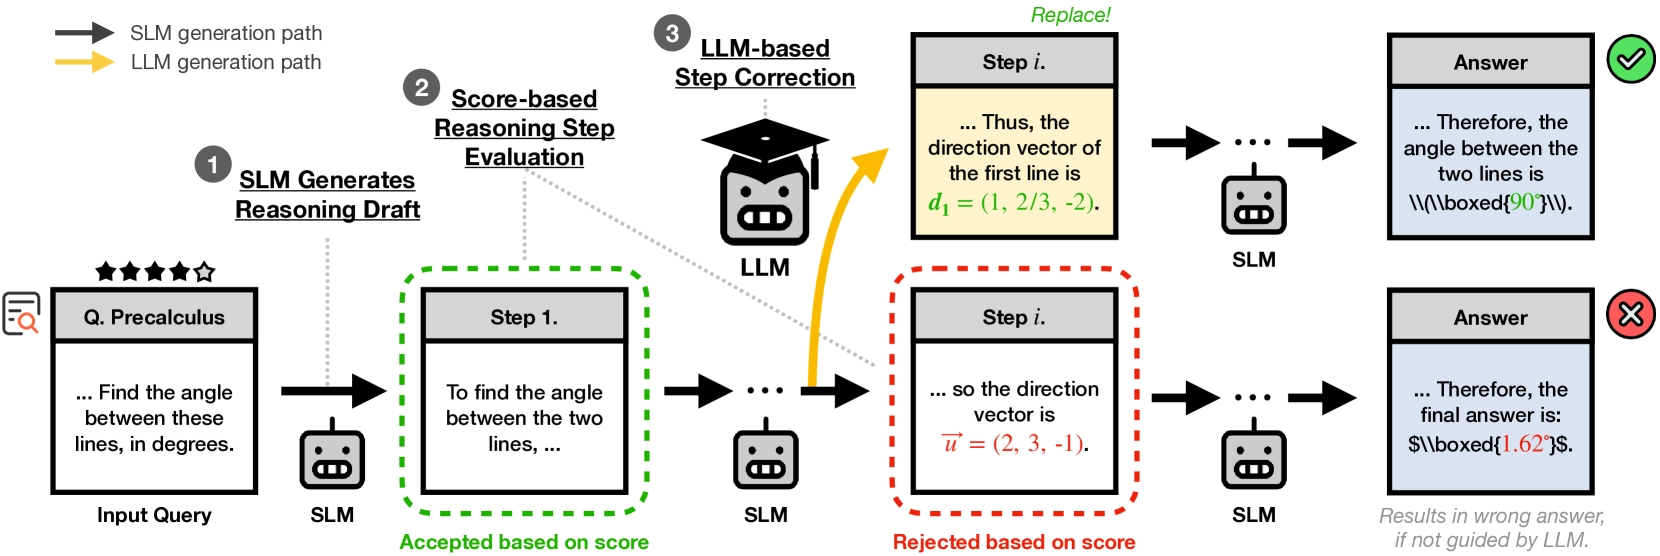

- 작동 방식
   - ① 간단한 작업: 문장 분류, 간단한 요약 등은 빠르고 효율적인 sLM이 처리
   - ② 복잡한 작업: 여러 단계의 추론이나 전문적인 분석이 필요한 작업은 LLM이 처리
   - ③ 결과: 모든 작업에 LLM을 사용하지 않아도 되므로 비용과 처리 시간을 줄이면서 필요한 수준의 성능 확보

> sLM의 효율성과 LLM의 높은 문제 해결 능력을 결합하여 성능과 비용 사이의 균형을 맞추는 방식

## 6. 생성 모델의 개념

### 6-1. 분류 모델 vs 생성 모델
- 생성 모델(Generative Model): 주어진 학습 데이터를 학습하고, 학습 데이터의 분포를 따르는 유사 데이터를 생성하는 모델

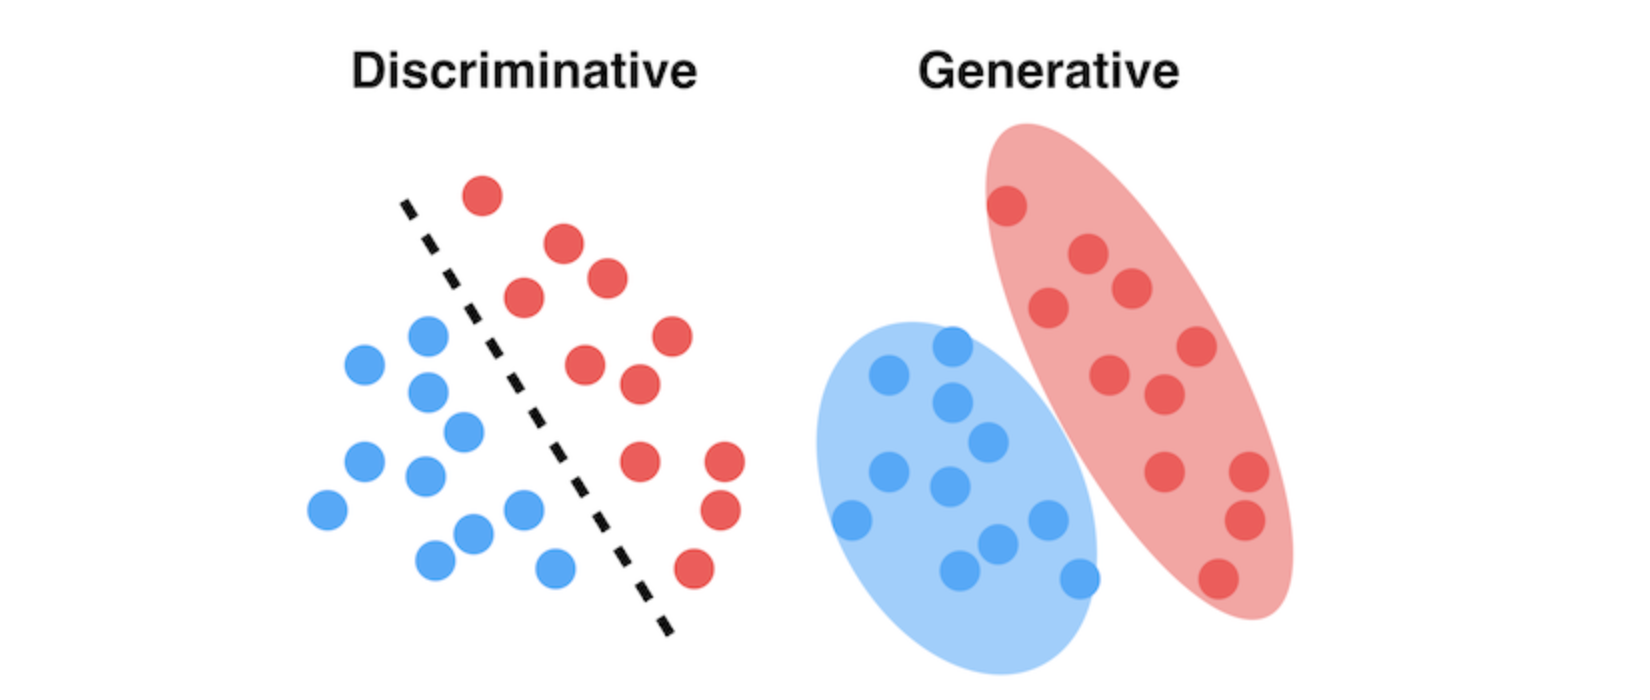

| 구분 | 분류 모델 | 생성 모델 |
|---|---|---|
| 학습 방법 | 데이터의 특징과 정답 레이블의 관계 학습 | 데이터의 특징과 확률분포 학습 |
| 학습 목표 | P(Y\|X) 모델링: 데이터 X가 주어졌을 때 정답 Y에 속할 확률을 학습하여 분류 | P(X) 모델링: 실제 데이터 X가 나타나는 확률분포를 학습하여 새로운 데이터 생성 |
| 주요 특징 | 데이터의 차이점을 학습하여 분류 기준 형성 | 데이터의 공통적인 특징과 다양한 패턴을 학습, 입력 데이터의 적합성 평가 및 비정상적인 입력 탐지에도 활용 |
| 출력 결과 | 범주 또는 범주별 예측 확률 | 새로운 이미지, 텍스트, 음성 등 |
| 한계 | 처음 보는 이상한 데이터도 학습한 라벨 중 하나로 잘못 분류할 수 있으며, 새로운 데이터 생성 불가 | 부자연스러운 결과 생성 가능, 생성 결과의 품질 평가 어려움 |

### 6-2. 생성 모델의 분류
- 생성 모델은 '데이터의 확률밀도를 직접 계산할 수 있는가?'에 따라 크게 두 가지로 나뉨

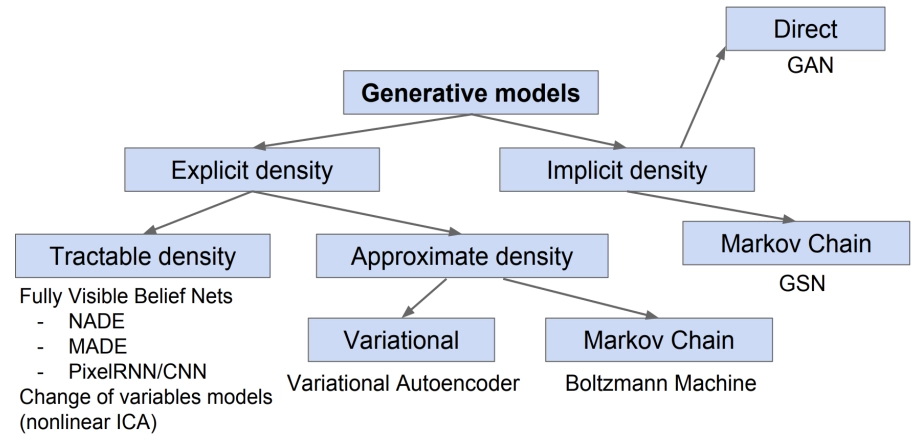

**1) 명시적 확률밀도 모델 (Explicit Density Model)**
- 데이터의 확률분포를 수학적으로 정의하고, 특정 데이터의 P(X) 값을 직접 수치화하여 출력할 수 있는 생성 모델
   - 확률밀도: 학습한 데이터의 분포에서 특정 데이터가 얼마나 그럴듯한지 나타내는 값

| 분류 | 내용 | 대표 모델 |
|---|---|---|
| 다루기 쉬운 밀도 모델 (Tractable Density) | 데이터의 확률밀도를 수학적으로 직접 계산할 수 있는 모델 | NADE, MADE, PixelRNN/PixelCNN, Change of Variables Model |
| 근사적 밀도 모델 (Approximate Density) | 확률밀도를 직접 계산하기 어려워 변분 추론이나 마르코프 연쇄 등 근사적인 방법 활용 | VAE(변분 추론), Boltzmann Machine(마르코프 연쇄) |

**2) 암시적 확률밀도 모델 (Implicit Density Model)**
- 데이터의 확률분포 P(X)를 수치로 알려주지 않고, 학습한 데이터의 분포를 바탕으로 새로운 데이터를 생성(Sampling)하는 데 초점을 맞춘 생성 모델
   - 데이터가 가지는 특징과 패턴을 학습하며, 특정 데이터의 확률밀도를 직접 계산하기는 어려움

| 분류 | 내용 | 대표 모델 |
|---|---|---|
| 직접 샘플링 (Direct Sampling) | 무작위 노이즈를 입력하여 생성 모델을 한 번 통과시켜 새로운 데이터를 직접 생성 | GAN |
| 간접/반복적 샘플링 (Indirect/Iterative Sampling) | 여러 단계의 확률적인 상태 변화를 반복하여 학습한 데이터의 분포를 따르는 표본 생성 | GSN |

## 7. AE, VAE

### 7-1. AE (Auto Encoder)

**1) 정의**
- 입력 데이터의 중요한 특징을 압축하고, 이를 바탕으로 원래 데이터와 최대한 유사하게 복원하도록 학습하는 인공신경망 모델
   - 입력 데이터와 복원된 데이터의 차이를 최소화하는 것이 목표
   - 별도의 정답 레이블 없이 입력 데이터 자체를 복원 목표로 활용
- 기존 인코더, 디코더와의 차이
   - 기존 인코더, 디코더: 입력 데이터를 이해하고 원하는 결과를 생성 (예: 한국어 문장 → 영어 번역문)
   - AE의 인코더, 디코더: 입력 데이터의 특징을 압축하고 원래 데이터로 복원 (예: 숫자 4 이미지 → 숫자 4 이미지)

**2) 구조와 작동 과정**

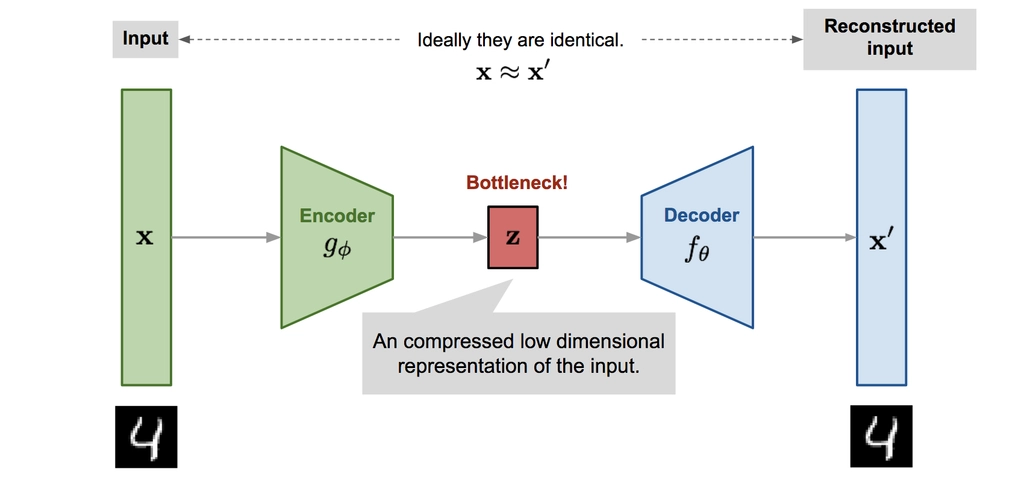

| 단계 | 내용 |
|---|---|
| ① 압축 단계 (Encoder) | 입력 데이터(x)에서 중요한 특징을 추출하여 더 적은 수의 값인 잠재 벡터(z)로 변환 |
| ② 병목 통과 (Bottleneck) | 핵심 정보를 잠재 벡터(Latent Vector, z)로 표현, 제한된 공간에 정보를 담아 핵심적인 특징을 학습하도록 유도 |
| ③ 복원 단계 (Decoder) | 잠재 벡터(z)로 원본과 유사한 복원 데이터(x')를 생성하고, 중요한 정보가 얼마나 보존되었는지 확인 |

**3) AE는 왜 압축했다가 복원할까?**
- 압축하는 이유: 압축하지 않으면 입력을 단순히 복사할 수 있으므로, 잠재공간의 크기를 제한하여 어떤 정보가 가장 중요한지 학습하게 함
- 복원하는 이유: 압축된 정보만으로 원본을 만들어낼 수 있는지 확인, 복원 오차(Reconstruction Error)를 줄이도록 학습
- 결과: 원본 데이터를 단순히 복사하는 것이 아니라 데이터의 핵심적인 특징과 구조(Non-trivial Structure)를 학습

**4) AE의 한계**
- 입력 데이터를 최대한 정확하게 복원하는 것이 주요 목표
- 잠재공간이 불규칙하게 형성되어 데이터가 존재하지 않는 빈 영역이 생길 수 있으며, 이 영역의 잠재 벡터를 디코더에 입력하면 부자연스러운 결과가 나올 수 있음

> 기존 데이터의 복원에는 효과적이지만, 임의의 잠재 벡터로 새로운 데이터를 안정적으로 생성하는 데 한계 → VAE 등장

### 7-2. VAE (Variational Auto Encoder)

**1) 정의**
- 입력 데이터의 특징을 확률분포로 학습하고, 해당 분포에서 샘플링하여 새로운 데이터를 생성할 수 있는 생성 모델
   - 기존 AE의 인코더, 디코더 구조를 기반으로 만들어진 모델
   - 변분 추론(Variational Inference)을 활용하여 복잡한 확률분포를 근사적으로 학습
   - 데이터의 특징을 가우시안 분포 형태로 학습하고, 잠재공간이 일정한 분포를 따르도록 학습 → 잠재공간에서 샘플링하여 기존과 유사한 새로운 데이터 생성 가능

**2) 학습 목표**
- 복원 오차(Reconstruction Loss) 최소화: 원본 데이터와 복원 데이터의 차이를 최소화
- KL 발산(KL Divergence) 최소화: 인코더가 예측한 잠재분포가 표준정규분포에 가까워지도록 학습
   - KL 발산: 두 확률분포가 얼마나 다른지를 수치로 나타내는 지표 (같으면 0, 차이가 클수록 큰 값)
- → 잠재공간이 불규칙하게 형성되는 문제를 완화하고, 새로운 데이터를 생성하기 좋은 잠재공간을 형성하도록 유도

**3) AE와 VAE의 차이**

| 구분 | AE | VAE |
|---|---|---|
| 잠재 표현 | 입력 데이터를 하나의 고정된 잠재 벡터(특정 위치의 점)로 표현 | 입력 데이터마다 평균(μ)과 분산(σ²)을 계산하여 확률분포 형태로 표현 |
| 잠재공간 | 일정한 분포를 따르지 않아 불규칙하게 형성, 빈 영역에서 추출하면 의미 없는 데이터 생성 가능 | 표준정규분포에 가까워지도록 학습하여 연속적이고 규칙적으로 형성 |
| 목적 | 입력 데이터의 압축과 복원 | 새로운 데이터 생성 |

> AE는 데이터의 특징을 하나의 점으로 표현하지만, VAE는 확률분포로 표현하여 다양한 값을 샘플링하고 새로운 데이터를 생성할 수 있음

**4) VAE의 구조와 작동 과정**

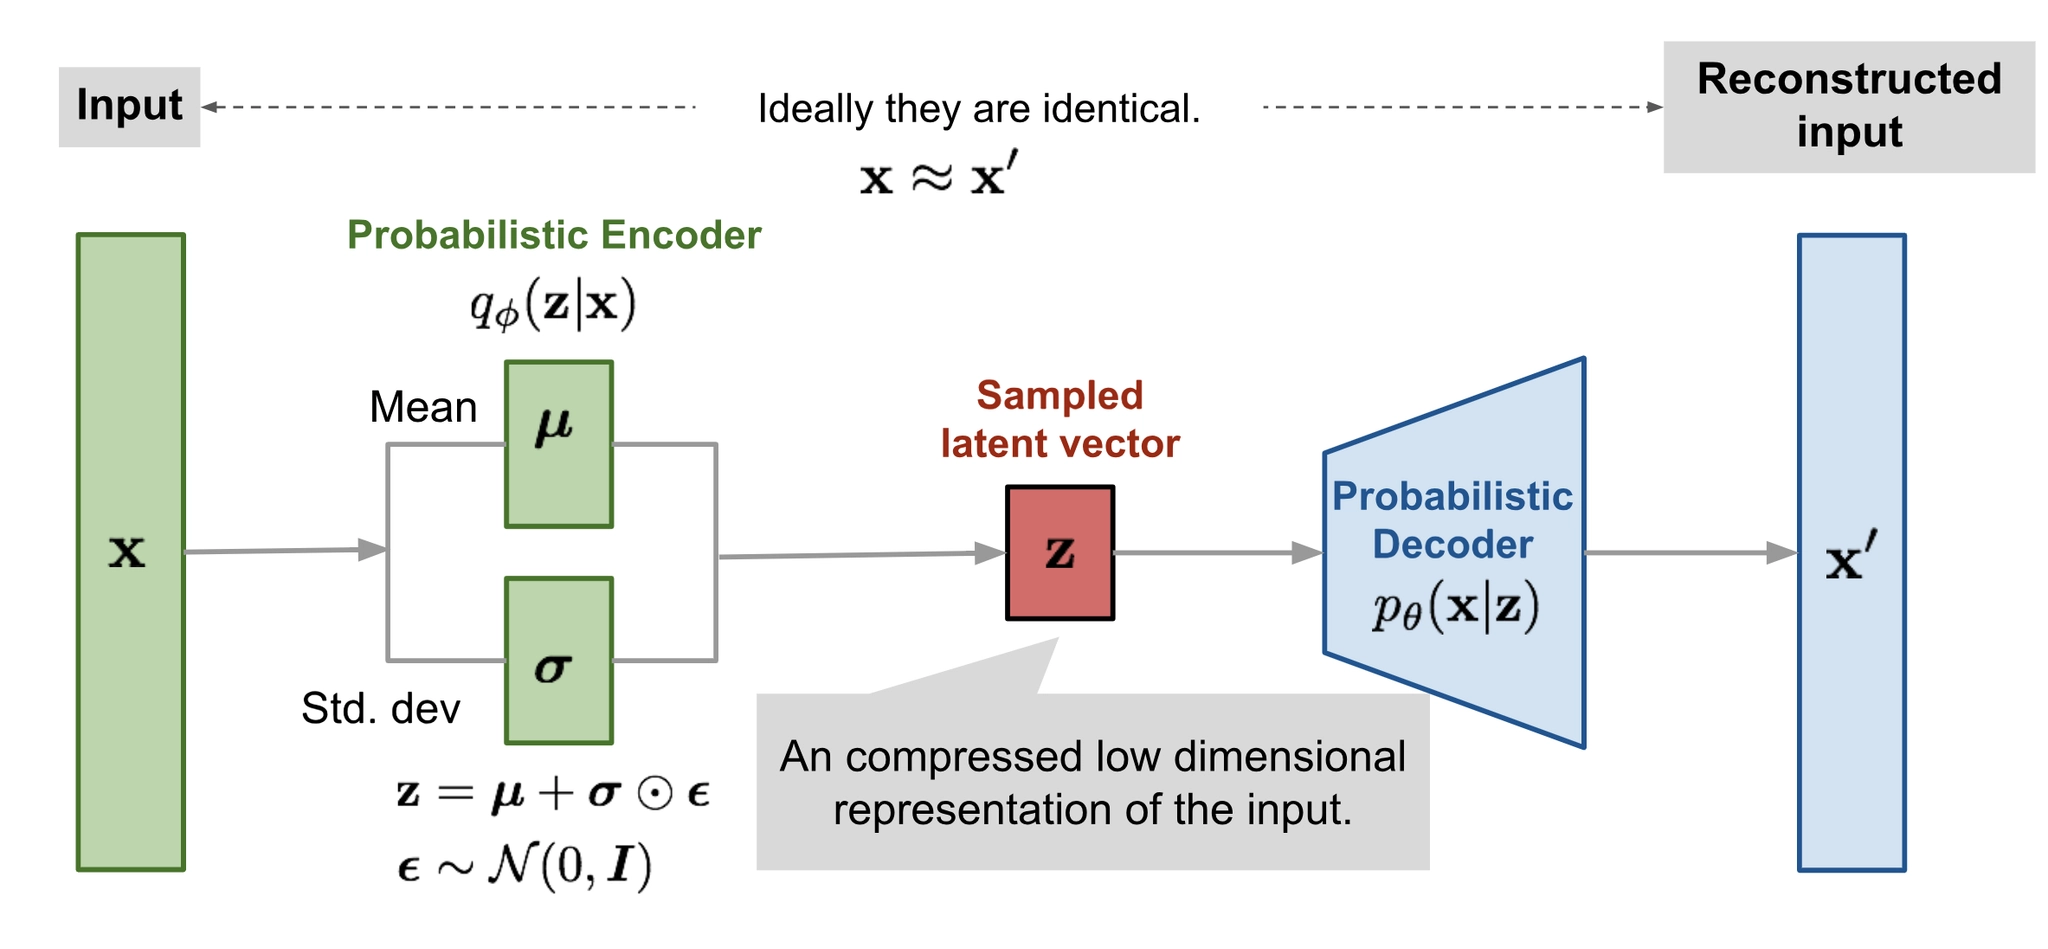

| 단계 | 내용 |
|---|---|
| ① 분포 예측 (Probabilistic Encoder) | 입력 데이터 x의 특징을 분석하여 평균(μ)과 표준편차(σ)를 예측하고 확률분포 형성, $q_\phi(z \mid x)$ |
| ② 샘플링 및 재파라미터화 | 예측한 확률분포에서 잠재 벡터 z를 무작위로 샘플링, $z = \mu + \sigma \odot \varepsilon$, $\varepsilon \sim \mathcal{N}(0, I)$ |
| ③ 생성 (Probabilistic Decoder) | 샘플링한 잠재 벡터 z로 데이터의 확률분포를 예측하고 이미지를 복원하거나 생성, $z \sim \mathcal{N}(0, I) \rightarrow x' \sim p_\theta(x \mid z)$ |

- 재파라미터화(Reparameterization Trick): 무작위 샘플링을 그대로 쓰면 기울기를 전달하기 어려우므로, 무작위성을 별도의 노이즈 변수(ε)로 분리하여 샘플링 과정에서도 신경망이 학습할 수 있도록 함
- 활용 분야: 이미지 생성, 데이터 증강, 이상 탐지, 특징 추출

> AE가 입력 데이터의 압축과 복원에 집중한다면, VAE는 확률분포를 학습하여 새로운 데이터까지 생성할 수 있도록 발전한 모델

## 8. GAN

### 8-1. GAN의 개념
- GAN(Generative Adversarial Network, 적대적 생성 신경망): 생성자(Generator)와 판별자(Discriminator)라는 두 신경망이 서로 경쟁하면서 실제 데이터와 유사한 새로운 데이터를 생성하도록 학습하는 생성 모델
   - 2014년 Ian Goodfellow 등이 제안
   - 생성자는 진짜 같은 가짜 데이터를 만들고, 판별자는 입력된 데이터가 진짜인지 가짜인지 구별 (예: 위조지폐범과 경찰)
   - 두 신경망이 서로 경쟁하며 학습하기 때문에 적대적(Adversarial) 생성 신경망이라고 부름

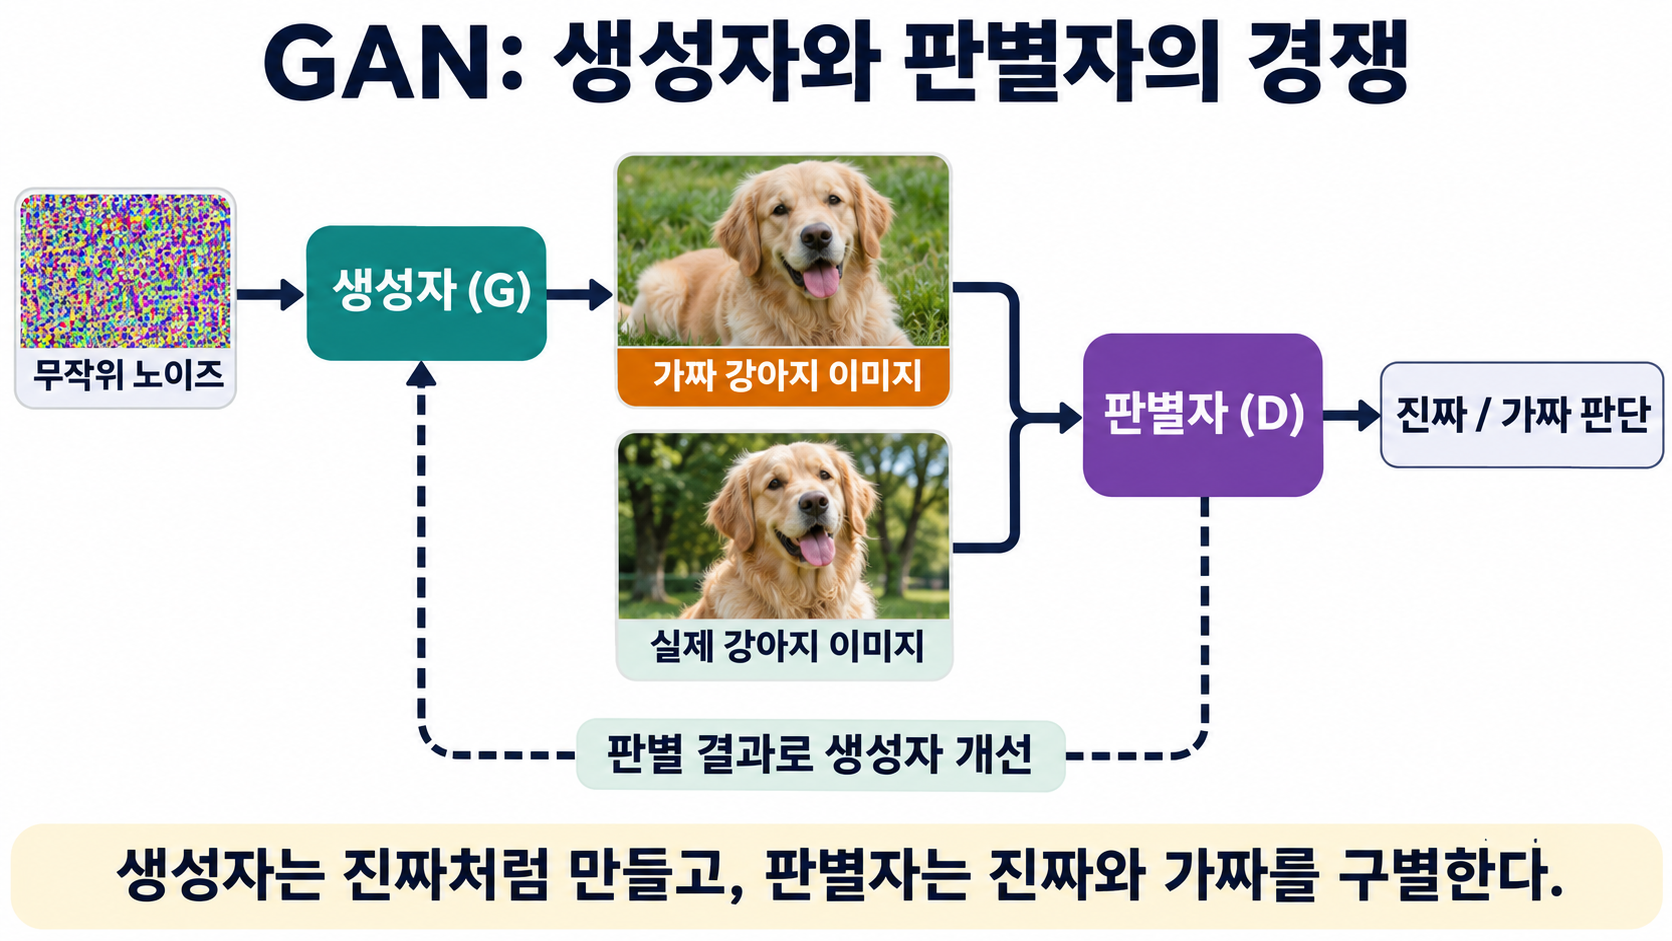

**1) GAN의 목적**
- 생성자: 판별자가 진짜라고 판단할 만큼 실제 데이터와 유사한 가짜 데이터 생성
- 판별자: 실제 데이터와 생성자가 만든 데이터를 최대한 정확하게 구별
- 궁극적인 목적: 경쟁을 통해 생성자가 실제 데이터의 분포를 학습하여, 실제 데이터와 구별하기 어려울 만큼 자연스러운 새로운 데이터를 생성하는 것

### 8-2. GAN의 구조
- 생성자와 판별자가 서로 반대되는 목표를 가지고 경쟁하며 학습하는 구조 → 최소-최대 게임(Minimax Game)

| 구성 요소 | 입력 | 출력 | 목표 |
|---|---|---|---|
| ① 무작위 노이즈 (z) | - | 생성자에 입력되는 무작위 숫자 벡터 | 새로운 이미지 생성의 재료 |
| ② 생성자 (G) | 무작위 노이즈(z) | 생성된 가짜 이미지 G(z) | 판별자가 진짜라고 판단할 만큼 실제와 유사한 이미지 생성 |
| ③ 판별자 (D) | 실제 이미지(x) 또는 가짜 이미지 G(z) | 입력 이미지가 진짜일 확률(0~1) | 실제 이미지에는 높은 확률, 가짜 이미지에는 낮은 확률 부여 |

> 판별자는 진짜와 가짜를 구별하는 능력을 최대화하고, 생성자는 판별자를 속이도록 학습하는 최소-최대 게임을 통해 실제 데이터와 유사한 이미지를 생성

### 8-3. GAN의 장단점

**1) 장점**
| 장점 | 내용 |
|---|---|
| ① 진짜 같은 가짜 생성 | 현실에 존재하지 않지만 실제처럼 보이는 데이터 생성 (예: 실존하지 않는 사람의 얼굴) |
| ② 높은 이미지 선명도 | VAE는 픽셀 간 평균값(MSE 등)을 최소화하여 이미지가 흐릿해지는 경향이 있지만, GAN은 판별자를 속여야 하므로 미세한 질감까지 살려 선명한 결과 생성 |
| ③ 빠른 생성 속도 | 무작위 노이즈를 생성자에 한 번 통과시키는 방식으로, 여러 단계를 반복하는 확산 모델보다 빠름 |
| ④ 잠재공간의 부드러움 | 잠재 벡터를 조금씩 변화시키면 생성 이미지의 특징도 자연스럽게 변화 (단, 모든 GAN에서 보장되지는 않음) |

**2) 한계**
| 한계 | 문제 | 해결 방법 |
|---|---|---|
| ① 학습의 불안정성 | 두 신경망의 학습 균형이 무너져 안정적인 학습이 어려움 (진동현상, 무한루프) | 학습률 및 학습 횟수 조절, WGAN-GP 등 개선된 모델 활용 |
| ② 훈련 초기 문제 | 학습 초기에 판별자가 가짜를 너무 쉽게 구별하여 생성자가 충분한 학습 신호(기울기)를 받지 못함 | Non-saturating Loss, 판별자의 학습 속도 조절 |
| ③ 모드 붕괴 (Mode Collapse) | 생성자가 판별자를 속이는 데 성공한 특정 형태의 데이터만 반복 생성하여 다양성 감소 | Minibatch Discrimination, WGAN-GP |
| ④ 평가 지표의 한계 | 사실성, 선명도, 다양성 등을 하나의 지표로 완벽하게 평가하기 어려움 | FID, IS 등 여러 정량적 지표와 사람의 시각적 평가 병행 |
| ⑤ 역매핑의 어려움 (Inverse Mapping) | 잠재 벡터 → 이미지의 단방향 구조로 학습하여, 실제 이미지에 해당하는 잠재 벡터를 찾기 어려움 | GAN Inversion, BiGAN |

## 9. 확산 모델

### 9-1. 확산 모델(Diffusion Model)의 개념
- 이미지에 노이즈(잡음)를 추가한 데이터를 학습하고, 무작위 노이즈를 점차 제거하면서 새로운 이미지를 생성하는 생성형 AI 모델
- 기본 원리
   - 실제 이미지에 노이즈를 조금씩 추가하면서 이미지가 흐트러지는 과정을 만듦
   - 모델은 노이즈가 포함된 이미지에서 노이즈를 제거하는 방법을 학습
   - 학습이 완료되면 무작위 노이즈에서 시작해 새로운 이미지를 만들어 냄
- 목적: 실제 데이터의 특징과 분포를 학습하여 새로운 데이터를 자연스럽고 다양하게 생성
   - 모호성 모델링(Ambiguity Modeling): 하나의 조건에서 여러 결과가 가능하다는 불확실성을 확률분포로 학습하여 다양한 결과물 생성

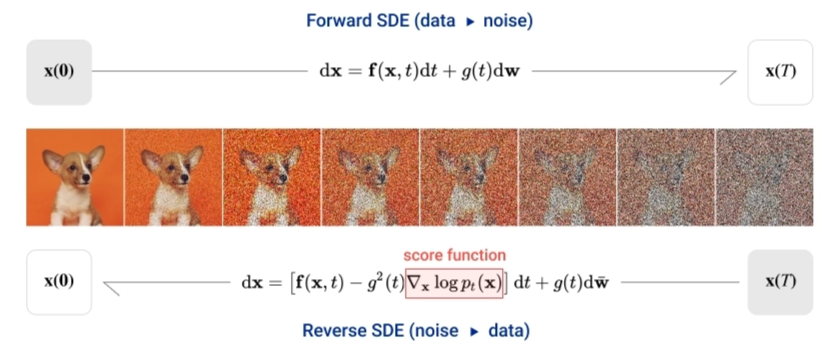

### 9-2. 확산 모델의 구조: 순확산과 역확산

| 구분 | 순확산 (Forward Diffusion) | 역확산 (Reverse Diffusion) |
|---|---|---|
| 개념 | 원본 이미지에 가우시안 노이즈를 조금씩 추가하여 최종적으로 무작위 노이즈에 가까운 상태로 만드는 과정 | 무작위 노이즈에서 시작하여 노이즈를 단계적으로 제거하면서 새로운 이미지를 생성하는 과정 (순확산의 반대 방향) |
| 목표 | 다양한 수준의 노이즈를 추가하여, 모델이 역확산에서 노이즈를 제거하는 방법을 학습할 수 있도록 함 | 학습한 노이즈 제거 방법으로 무작위 노이즈를 실제와 유사한 자연스러운 이미지로 바꿈 |
| 시작 | 노이즈가 없는 깨끗한 원본 이미지 ($x_0$) | 무작위 노이즈 ($x_T$) |
| 진행 | 가우시안 노이즈(정규분포를 따르는 무작위 잡음)를 여러 단계에 걸쳐 추가 ($x_1, x_2, \dots$) → 단계가 진행될수록 이미지가 흐려짐 | 학습된 Denoising U-Net이 현재 이미지의 노이즈를 예측하고 조금씩 제거하는 과정을 여러 번 반복 → 색상과 윤곽이 점차 나타남 |
| 결과 | 원본의 특징이 거의 사라진 무작위 노이즈 ($x_T$) | 새로운 이미지 ($x_0$) |

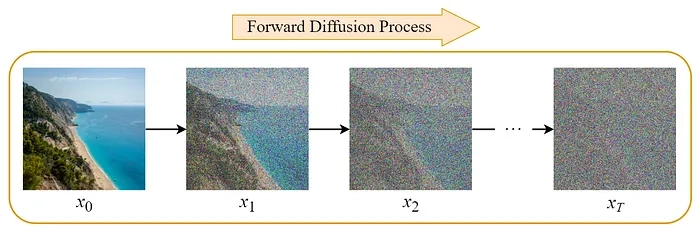

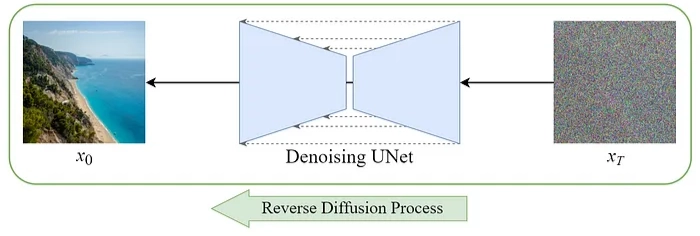

> 순확산으로 만든 노이즈 데이터로 노이즈 제거 방법을 학습하고, 역확산에서 이를 반복 적용하여 새로운 이미지를 생성

### 9-3. 확산 모델의 장단점
| 구분 | 내용 |
|---|---|
| 장점: 압도적인 샘플 품질 | 노이즈를 단계적으로 제거하여 GAN보다 정교하고 다양한 고품질 이미지 생성에 유리 |
| 장점: 학습의 안정성 | 경쟁 방식이 아닌 노이즈 예측·제거 방식으로 학습, MSE로 학습 과정을 수치로 확인 가능 → GAN에 비해 안정적 |
| 장점: 다양성 확보 | 무작위 노이즈에서 시작하므로 같은 조건에서도 서로 다른 이미지 생성 가능 |
| 단점: 느린 생성 속도 | 여러 단계에 걸쳐 노이즈를 반복적으로 제거해야 하므로 GAN에 비해 생성 시간이 오래 걸림 |
| 단점: 높은 계산 비용 | 학습과 생성 모두 많은 연산이 필요하여 고성능 하드웨어와 자원 소모가 큼 |
| 단점: 구조적 제약 | 순확산과 역확산의 단계적 구조에 의존하여 과정을 자유롭게 변경하기 어렵고, 노이즈 제거 단계의 수와 방식에 따라 속도와 품질이 달라짐 |